Running 500-trial Monte Carlo uncertainty propagation...

 MONTE CARLO UNCERTAINTY RESULTS
Input Tracking Noise Assumed: sigma = 5.0 mm
Flight Time: 0.3901 +/- 0.0057 s
Goal Width (Y):    3.299 +/- 0.039 m
Goal Height (Z):   1.906 +/- 0.041 m
95% Confidence Interval Y: [3.232, 3.379] m
95% Confidence Interval Z: [1.818, 1.988] m


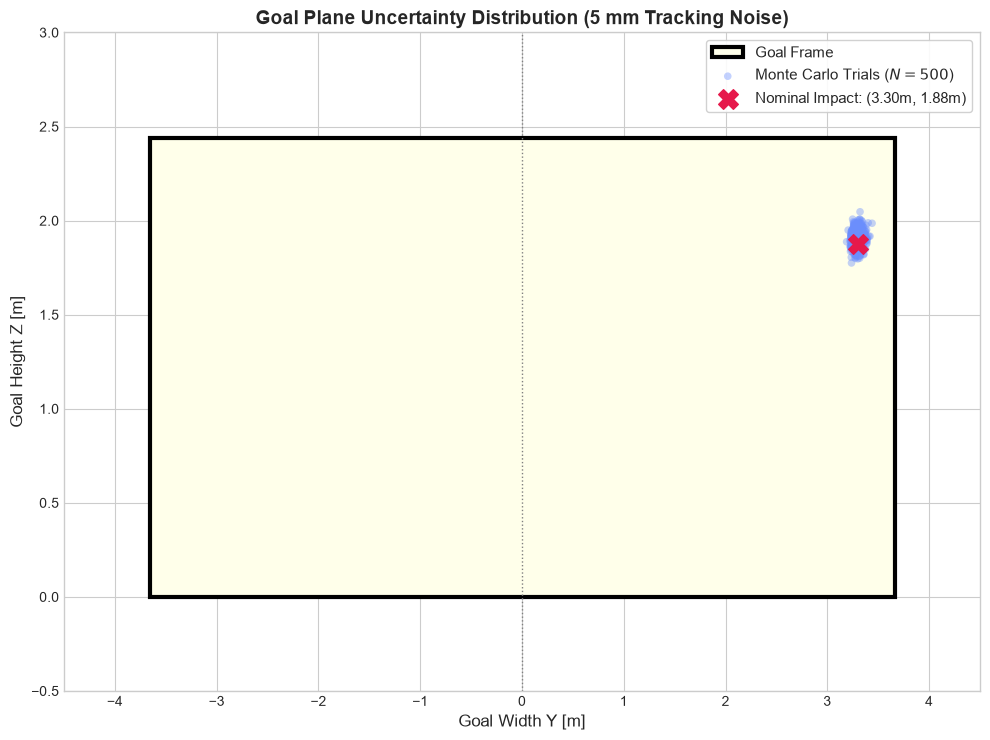

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy.integrate import solve_ivp

# --- 1. System Parameters & Setup ---
g = 9.81
k_nom = 0.5405
r0 = np.array([0.0, 0.0, 0.11])
v0_nom = np.array([30.405, 9.122, 6.933])

def simulate_impact(v0, k_val):
    """Solves ODE and returns flight time and (y, z) goal crossing coordinates."""
    state0 = np.concatenate([r0, v0])
    def eq(t, s):
        x, y, z, vx, vy, vz = s
        return [vx, vy, vz, -k_val*vx, -k_val*vy, -g - k_val*vz]
    
    def hit_goal(t, s):
        return s[0] - 11.0
    hit_goal.terminal = True
    hit_goal.direction = 1
    
    sol = solve_ivp(eq, (0.0, 0.6), state0, events=hit_goal, max_step=0.001)
    return sol.t[-1], sol.y[1][-1], sol.y[2][-1]

# Nominal trajectory impact
t_nom, y_nom, z_nom = simulate_impact(v0_nom, k_nom)

# --- 2. Monte Carlo Noise Simulation (N = 500) ---
np.random.seed(42)
N = 500
sigma_r = 0.005  # 5 mm standard deviation for tracking noise
dt = 0.05

t_pts, y_pts, z_pts = [], [], []

for _ in range(N):
    r1_pert = np.array([1.50, 0.45, 0.44]) + np.random.normal(0, sigma_r, 3)
    r2_pert = np.array([2.96, 0.86, 0.74]) + np.random.normal(0, sigma_r, 3)
    
    v_x1 = r1_pert[0] / dt
    v_x2 = (r2_pert[0] - r1_pert[0]) / dt
    k_pert = max(0.01, -(v_x2 - v_x1) / (r2_pert[0] - 0.5 * r1_pert[0]))
    
    vx0 = v_x1 + k_pert * (0.5 * r1_pert[0])
    vy0 = (r1_pert[1] / r1_pert[0]) * vx0
    vz0 = ((r1_pert[2] - 0.11) / dt) + (k_pert * (r1_pert[2] - 0.11) / 2.0) + (0.5 * g * dt)
    
    try:
        t_g, y_g, z_g = simulate_impact(np.array([vx0, vy0, vz0]), k_pert)
        t_pts.append(t_g)
        y_pts.append(y_g)
        z_pts.append(z_g)
    except:
        pass

# --- 3. Monte Carlo Uncertainty Results ---
flight_mean, flight_std = np.mean(t_pts), np.std(t_pts, ddof=1)
y_mean, y_std = np.mean(y_pts), np.std(y_pts, ddof=1)
z_mean, z_std = np.mean(z_pts), np.std(z_pts, ddof=1)
y_ci = np.percentile(y_pts, [2.5, 97.5])
z_ci = np.percentile(z_pts, [2.5, 97.5])

print(f"Running {len(y_pts)}-trial Monte Carlo uncertainty propagation...")
print("\n==========================================")
print(" MONTE CARLO UNCERTAINTY RESULTS")
print("==========================================")
print(f"Input Tracking Noise Assumed: sigma = {sigma_r * 1000:.1f} mm")
print(f"Flight Time: {flight_mean:.4f} +/- {flight_std:.4f} s")
print(f"Goal Width (Y):    {y_mean:.3f} +/- {y_std:.3f} m")
print(f"Goal Height (Z):   {z_mean:.3f} +/- {z_std:.3f} m")
print(f"95% Confidence Interval Y: [{y_ci[0]:.3f}, {y_ci[1]:.3f}] m")
print(f"95% Confidence Interval Z: [{z_ci[0]:.3f}, {z_ci[1]:.3f}] m")

# --- 4. Figure Rendering (Matching Target Style) ---
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, ax = plt.subplots(figsize=(10, 7.5))

# Goal frame (-3.66 to 3.66 m wide, 0 to 2.44 m tall)
goal_rect = Rectangle((-3.66, 0), 7.32, 2.44, facecolor='#FFFFEA', edgecolor='black', lw=3, label='Goal Frame')
ax.add_patch(goal_rect)

# Midline reference
ax.axvline(0, color='gray', linestyle=':', lw=1)

# Scatter points for Monte Carlo trials
ax.scatter(y_pts, z_pts, color='#6B8EFE', alpha=0.4, edgecolors='none', s=30, 
           label=f'Monte Carlo Trials ($N = {len(y_pts)}$)')

# Mean Impact Marker
ax.scatter(y_nom, z_nom, color='#E6194B', marker='X', s=200, 
           label=f'Nominal Impact: ({y_nom:.2f}m, {z_nom:.2f}m)')

# Axis Formatting
ax.set_xlim(-4.5, 4.5)
ax.set_ylim(-0.5, 3.0)
ax.set_xlabel('Goal Width Y [m]', fontsize=12)
ax.set_ylabel('Goal Height Z [m]', fontsize=12)
ax.set_title('Goal Plane Uncertainty Distribution (5 mm Tracking Noise)', fontsize=14, fontweight='bold')

ax.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=11, loc='upper right')

plt.tight_layout()
plt.show()